#Spam Message Classifier
**Goal:** Train a machine-learning model to classify SMS messages as `spam` or `ham` (legitimate).

**Dataset:** UCI SMS Spam Collection (downloaded automatically by the notebook).
**Methods:** TF-IDF text features + Multinomial Naive Bayes.

```
# This is formatted as code
```


**Evaluation:** Test-set accuracy, precision, recall, F1-score, confusion matrix, and custom predictions.

In [ ]:
%pip install -q pandas scikit-learn matplotlib

## 2. Import libraries

In [1]:
import io
import zipfile
import urllib.request
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, classification_report, ConfusionMatrixDisplay,
    confusion_matrix
)

RANDOM_STATE = 42

## 3. Download and load the dataset
The notebook saves a copy under `data/` so you do not need to download it manually.

In [2]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
ZIP_PATH = DATA_DIR / "sms_spam_collection.zip"
CSV_PATH = DATA_DIR / "SMSSpamCollection"

if not CSV_PATH.exists():
    print("Downloading the UCI SMS Spam Collection...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        # The UCI archive contains a file named SMSSpamCollection.
        member = next(name for name in archive.namelist()
                      if name.endswith("SMSSpamCollection"))
        CSV_PATH.write_bytes(archive.read(member))

df = pd.read_csv(
    CSV_PATH, sep="\t", header=None, names=["label", "message"],
    encoding="utf-8"
)
df = df.dropna().drop_duplicates().reset_index(drop=True)
df["label"] = df["label"].str.strip().str.lower()

print("Dataset shape:", df.shape)
display(df.head())
print("\nClass counts:")
display(df["label"].value_counts())

Dataset shape: (5169, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Class counts:


,count
label,
ham,4516
spam,653


## 4. Explore the data

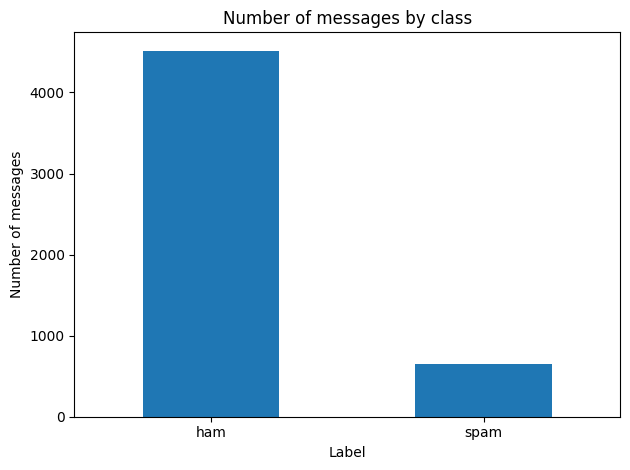

Missing values:


,0
label,0
message,0


In [3]:
df["label"].value_counts().plot(kind="bar", rot=0)
plt.title("Number of messages by class")
plt.xlabel("Label")
plt.ylabel("Number of messages")
plt.tight_layout()
plt.show()

print("Missing values:")
display(df.isna().sum())

## 5. Split the data and train the model
We use a stratified train/test split so the proportion of spam and legitimate messages stays similar in both sets. The TF-IDF vectorizer is inside a pipeline, which means it learns vocabulary from the training data only and helps prevent data leakage.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df["message"],
    df["label"],
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df["label"]
)

spam_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2
    )),
    ("classifier", MultinomialNB())
])

spam_model.fit(X_train, y_train)
print(f"Training examples: {len(X_train):,}")
print(f"Test examples: {len(X_test):,}")
print("Training complete.")

Training examples: 4,135
Test examples: 1,034
Training complete.


## 6. Evaluate on the held-out test set

Accuracy: 0.9691

Classification report:
              precision    recall  f1-score   support

         ham     0.9658    1.0000    0.9826       903
        spam     1.0000    0.7557    0.8609       131

    accuracy                         0.9691      1034
   macro avg     0.9829    0.8779    0.9217      1034
weighted avg     0.9701    0.9691    0.9672      1034



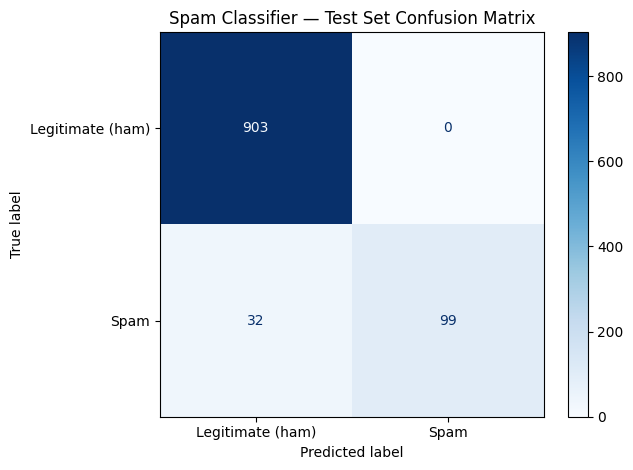

In [5]:
y_pred = spam_model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=["ham", "spam"],
    display_labels=["Legitimate (ham)", "Spam"],
    cmap="Blues", values_format="d"
)
plt.title("Spam Classifier — Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

## 7. Try your own messages

In [6]:
examples = [
    "Congratulations! You have won a free prize. Call now to claim.",
    "Hi, are we still meeting for lunch at 1 pm?",
    "URGENT! Your account has been selected for a cash reward."
]

for message in examples:
    prediction = spam_model.predict([message])[0]
    probabilities = spam_model.predict_proba([message])[0]
    classes = spam_model.named_steps["classifier"].classes_
    confidence = probabilities[list(classes).index(prediction)]
    print(f"Message: {message}")
    print(f"Prediction: {prediction.upper()} (model probability: {confidence:.1%})")
    print("-" * 70)

Message: Congratulations! You have won a free prize. Call now to claim.
Prediction: SPAM (model probability: 94.6%)
----------------------------------------------------------------------
Message: Hi, are we still meeting for lunch at 1 pm?
Prediction: HAM (model probability: 99.1%)
----------------------------------------------------------------------
Message: URGENT! Your account has been selected for a cash reward.
Prediction: SPAM (model probability: 71.7%)
----------------------------------------------------------------------
